In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
from utils import (get_data, calc_hist, get_rc_and_err, get_rc_and_err_unweighted, get_rc_and_err_new)

In [2]:
EMB_FILE   = '/nfs/roberts/home/ys668/output/run12/all050124_rc_notrueptcons.root'
EMB_CSV    = '/nfs/roberts/home/ys668/output/run12/all050124_rc_notrueptcons.csv'
DATA_FILE  = '/nfs/roberts/pi/pi_lbh35/youqi/data0613_chargedrc.root'
RESULT_CSV = '/nfs/roberts/home/ys668/output/run12/rc_corrected.csv'

COLUMNS   = ['pt', 'b', 'w', 'y1', 'y2', 'phi1', 'phi2',
             'pts', 'bs', 'ws', 'y1s', 'y2s', 'phi1s', 'phi2s', 'nefs']

PT_EDGES  = [15, 20, 25, 30, 40, 60]
PT_CENTERS = [17.5, 22.5, 27.5, 35, 50]
PT_XERR    = [2.5, 2.5, 2.5, 5, 10]

In [3]:
def bin_df_in_pts(df, col='pts'):
    return [df[(df[col] > PT_EDGES[i]) & (df[col] < PT_EDGES[i+1])] for i in range(5)]

def delta_phi(a, b):
    diff = np.abs(a - b)
    return np.minimum(diff, 2 * np.pi - diff)

def get_rc_and_err_arr(df_arr, ob):
    rc_arr = []
    err_arr = []
    for df in df_arr:
        rc, err = get_rc_and_err(df, ob)
        rc_arr.append(rc)
        err_arr.append(err)
    return rc_arr, err_arr

def get_rc_and_err_unweighted_arr(df_arr, ob):
    rc_arr = []
    err_arr = []
    for df in df_arr:
        rc, err = get_rc_and_err_unweighted(df, ob)
        rc_arr.append(rc)
        err_arr.append(err)
    return rc_arr, err_arr

def get_rc_and_err_new_arr(df_arr, ob):
    rc_arr = []
    err_arr = []
    for df in df_arr:
        rc, err = get_rc_and_err_new(df, ob)
        rc_arr.append(rc)
        err_arr.append(err)
    return rc_arr, err_arr

# Process PYTHIA6+GEANT

In [4]:
# One-time: load from ROOT, process and save to CSV
df_allreco = get_data(COLUMNS, EMB_FILE, 'MatchedTree').query('pts>15 and bs!=-9 and w<1').copy()
df_allreco['distance1'] = np.sqrt(
    delta_phi(df_allreco['phi1'].values, df_allreco['phi1s'].values)**2
    + (df_allreco['y1'].values - df_allreco['y1s'].values)**2)
df_allreco['distance2'] = np.sqrt(
    delta_phi(df_allreco['phi2'].values, df_allreco['phi2s'].values)**2
    + (df_allreco['y2'].values - df_allreco['y2s'].values)**2)
df_allreco.to_csv(EMB_CSV, index=False)

In [5]:
# Normal path: load from CSV
df_allreco = pd.read_csv(EMB_CSV, low_memory=False).query('pts>15 and bs!=-9 and w<1')
df_match   = df_allreco.query('pt!=-9 and b!=-9 and distance1<0.02 and distance2<0.02')
df_allfake = df_allreco.query('pt==-9 or b==-9 or distance1>0.02 or distance2>0.02')
print(df_match.shape[0], df_allfake.shape[0])

2630097 1465062


In [6]:
df_allreco_pts = bin_df_in_pts(df_allreco)
df_match_pts   = bin_df_in_pts(df_match)
df_allfake_pts = bin_df_in_pts(df_allfake)

In [7]:
rc_allreco, err_allreco = get_rc_and_err_arr(df_allreco_pts, 'bs')
rc_match,   err_match   = get_rc_and_err_arr(df_match_pts,   'bs')
rc_allfake, err_allfake = get_rc_and_err_arr(df_allfake_pts, 'bs')

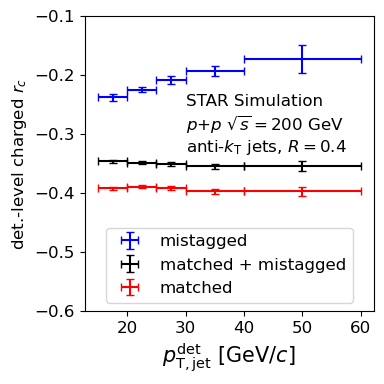

In [8]:
plt.rcParams['font.size'] = 12
fig, ax = plt.subplots(figsize=(4, 4))
ax.errorbar(PT_CENTERS, rc_allfake, xerr=PT_XERR, yerr=err_allfake, capsize=3, color='b', ls='none', label='mistagged')
ax.errorbar(PT_CENTERS, rc_allreco, xerr=PT_XERR, yerr=err_allreco, capsize=3, color='k', ls='none', label='matched + mistagged')
ax.errorbar(PT_CENTERS, rc_match,   xerr=PT_XERR, yerr=err_match,   capsize=3, color='r', ls='none', label='matched')
ax.set_xlabel(r'$p_{\mathrm{T,jet}}^{\mathrm{det}}$ [GeV$/c$]', fontsize=15)
ax.set_ylabel('det.-level charged $r_c$')
ax.set_ylim(-0.6, -0.1)
ax.legend(loc='lower center')
ax.text(30, -0.33, 'STAR Simulation\n$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')
plt.tight_layout()

In [9]:
RANGE_LOW, RANGE_HIGH, N_BINS = -1.2, 1.2, 2
b_bins = np.arange(RANGE_LOW, RANGE_HIGH + (RANGE_HIGH - RANGE_LOW) / N_BINS,
                   (RANGE_HIGH - RANGE_LOW) / N_BINS)

b_fake_array = []
for df_f in df_allfake_pts:
    y, _, _ = calc_hist(df_f['bs'], bins=b_bins, weights=df_f['ws'], density=True)
    b_fake_array.append(y / sum(y))

b_match_array, b_match_err_array = [], []
for df_m in df_match_pts:
    y, _, _ = calc_hist(df_m['bs'], bins=b_bins, weights=df_m['ws'], density=True)
    b_match_array.append(y / sum(y))
    p, q = y[0] / sum(y), y[1] / sum(y)
    eff, eff_err, _ = calc_hist(df_m['bs'], bins=[RANGE_LOW, RANGE_HIGH], weights=df_m['ws'], density=True)
    sqrt_n_over_n = eff_err[0] / eff[0]
    b_match_err_array.append(np.array([np.sqrt(p * q) * sqrt_n_over_n] * 2))

In [10]:
matched_mask = ((df_allreco.pt != -9) & (df_allreco.b != -9) & (df_allreco.distance1 < 0.02) & (df_allreco.distance2 < 0.02))
match_fake, _ = np.histogram(df_allreco['pts'],                 bins=PT_EDGES, weights=df_allreco['ws'])
match, _      = np.histogram(df_allreco[matched_mask]['pts'],   bins=PT_EDGES, weights=df_allreco[matched_mask]['ws'])
fake_rate_array = 1 - match / match_fake
fake_rate_array

array([0.29936725, 0.24871326, 0.22291703, 0.2064793 , 0.19306711])

# Process data

In [11]:
tree_data  = uproot.open(DATA_FILE)['ResultTree'].arrays(['pt', 'b'], library='np')
df_data = pd.DataFrame({
    'pts': np.concatenate(tree_data['pt']),
    'bs':  np.concatenate(tree_data['b']),
}).query('pts>15 and bs!=-9 and bs!=0')

In [12]:
df_data_pts = bin_df_in_pts(df_data)

rc_data, err_data = get_rc_and_err_unweighted_arr(df_data_pts, 'bs')

In [13]:
b_data_array = []
for df_d in df_data_pts:
    y, _, _ = calc_hist(df_d['bs'], bins=b_bins)
    b_data_array.append(y)
print(b_data_array)

[array([337314., 178144.]), array([72379., 38554.]), array([16450.,  8688.]), array([4758., 2573.]), array([334., 153.])]


# 1. Mistagged subtraction

In [14]:
def get_matched_count_and_err(data, fake_rate, fake_dist):
    corrected = data - sum(data) * fake_rate * fake_dist
    err = np.sqrt(corrected)
    return corrected, err

In [15]:
b_fakesubtracted_array, b_fakesubtractederr_array = [], []
rc1_array, rc1_err_array = [], []

for i in range(5):
    b_sub, _ = get_matched_count_and_err(b_data_array[i], fake_rate_array[i], b_fake_array[i])
    nos, nss = b_sub[0], b_sub[1]
    n, p = nos + nss, nss / (nos + nss)
    rc1_array.append((nss - nos) / n)
    rc1_err_array.append(2 * np.sqrt(p * (1 - p) / n))
    b_fakesubtracted_array.append(b_sub)
    b_fakesubtractederr_array.append(np.array([np.sqrt(p * (1 - p) / n)] * 2) * sum(b_sub)) # first find sigma(p), then scale up

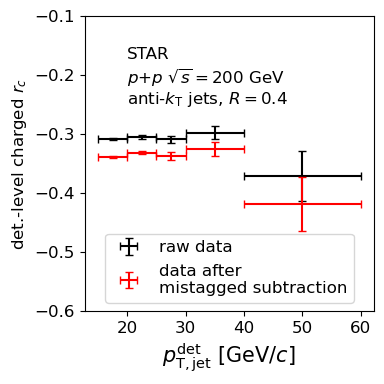

In [16]:
fig, ax = plt.subplots(figsize=(4, 4))
ax.errorbar(PT_CENTERS, rc_data,   xerr=PT_XERR, yerr=err_data,    capsize=3, color='k', ls='none', label='raw data')
ax.errorbar(PT_CENTERS, rc1_array, xerr=PT_XERR, yerr=rc1_err_array, capsize=3, color='r', ls='none', label='data after\nmistagged subtraction')
ax.set_xlabel(r'$p_{\mathrm{T,jet}}^{\mathrm{det}}$ [GeV$/c$]', fontsize=15)
ax.set_ylabel('det.-level charged $r_c$')
ax.set_ylim(-0.6, -0.1)
ax.legend(loc='lower center')
ax.text(20, -0.25, 'STAR\n$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')
plt.tight_layout()

# 2. $p_T$ correction

In [17]:
reweight_array, reweight_err_array = [], []
for i in range(5):
    num     = b_fakesubtracted_array[i] / sum(b_fakesubtracted_array[i])
    denom   = b_match_array[i]          / sum(b_match_array[i])
    num_err = b_fakesubtractederr_array[i] / sum(b_fakesubtracted_array[i])
    den_err = b_match_err_array[i]         / sum(b_match_array[i])
    rw      = num / denom
    reweight_array.append(rw)
    reweight_err_array.append(rw * np.sqrt((num_err / num)**2 + (den_err / denom)**2))

reweight_array

[array([0.96173176, 1.08767168]),
 array([0.95812662, 1.09532818]),
 array([0.960938  , 1.08943732]),
 array([0.94857114, 1.11921181]),
 array([1.01571797, 0.96355909])]

## Reweight PYTHIA6+GEANT

In [18]:
rw = np.array(reweight_array)   # shape (5, 2): rw[i,0]=os weight, rw[i,1]=ss weight
pts_vals = df_match['pts'].values
bs_vals  = df_match['bs'].values
bin_idx  = np.clip(np.digitize(pts_vals, PT_EDGES) - 1, 0, 4)
df_match = df_match.copy()
df_match['r'] = np.where(bs_vals == -1, rw[bin_idx, 0], rw[bin_idx, 1])

## Central values for $r_c$ and statistical uncertainty due to finite number of embedding jets being reweighted

In [19]:
df_match_pt = bin_df_in_pts(df_match, col='pt')

rc_match_corrected, err_match_corrected = get_rc_and_err_new_arr(df_match_pt, 'bs')
rc_match_corrected, err_match_corrected

([np.float64(-0.3362253643675409),
  np.float64(-0.3181884886244119),
  np.float64(-0.3182451746120078),
  np.float64(-0.31383135754427705),
  np.float64(-0.335649474166394)],
 [np.float64(0.00290975962520561),
  np.float64(0.0022640574993937684),
  np.float64(0.002823487231112133),
  np.float64(0.003506955202836532),
  np.float64(0.005239580870689935)])

In [35]:
df_match.to_csv(RESULT_CSV, index=False)

# Statistical uncertainty from `reweight_err_array`

In [20]:
# 3-return variant: also returns overall p = N_ss / N_total
def _get_rc_p(df, ob):
    if ob == 'b':
        nos, nss = sum(df[df.b == -1]['w']),  sum(df[df.b == +1]['w'])
    elif ob == 'b_ch':
        nos, nss = sum(df[df.b_ch == -1]['w']), sum(df[df.b_ch == +1]['w'])
    elif ob == 'bs':
        nos, nss = sum(df[df.bs == -1]['ws']), sum(df[df.bs == +1]['ws'])
    else:
        raise ValueError(f"Unknown observable '{ob}'")
    rc = (nss - nos) / (nss + nos)
    p_final = nss / (nss + nos)
    w_array = np.unique(df['w'])
    err2_array = []
    for w_i in w_array:
        mask = df.w == w_i
        if ob == 'b':
            p = sum(df[mask & (df.b == +1)]['w'])  / sum(df[mask]['w'])
        elif ob == 'b_ch':
            p = sum(df[mask & (df.b_ch == +1)]['w']) / sum(df[mask]['w'])
        elif ob == 'bs':
            p = sum(df[mask & (df.bs == +1)]['w'])  / sum(df[mask]['ws'])
        variance = p * (1 - p) / df[mask].shape[0]
        w = sum(df[mask]['w']) / sum(df['w'])
        err2_array.append(w**2 * variance)
    rc_err = 2 * np.sqrt(sum(err2_array))
    return rc, rc_err, p_final

In [21]:
rwerr_match_corrected = []

for i in range(5):
    df_cut_pt = df_match[(df_match['pt'] > PT_EDGES[i]) & (df_match['pt'] < PT_EDGES[i+1])]
    df_cut_pt_pts = bin_df_in_pts(df_cut_pt)
    df_cut_pt_ss  = df_cut_pt.query('bs==1')
    
    prob_ss_array = []
    p_array = []
    for j in range(5):
        _, _, p = _get_rc_p(df_cut_pt_pts[j], 'bs')
        prob_ss = sum(df_cut_pt_ss[(df_cut_pt_ss.pts > PT_EDGES[j]) & (df_cut_pt_ss.pts < PT_EDGES[j+1]) & (df_cut_pt_ss.pt > PT_EDGES[i]) & (df_cut_pt_ss.pt < PT_EDGES[i+1])]['w']) / sum(df_cut_pt_ss[(df_cut_pt_ss.pt > PT_EDGES[i]) & (df_cut_pt_ss.pt < PT_EDGES[i+1])]['w'])
        prob_ss_array.append(prob_ss)
        p_array.append(p)
    p_err = np.sqrt(sum((reweight_err_array[j][1] * p_array[j] * prob_ss_array[j])**2 for j in range(5)))
    rwerr_match_corrected.append(2 * p_err)

In [22]:
rwerr_match_corrected

[np.float64(0.0033147188333123726),
 np.float64(0.0028158457132233506),
 np.float64(0.003936762249902962),
 np.float64(0.007198410796846172),
 np.float64(0.021340253039584964)]

# Plot result

In [23]:
rc_rwerr = np.asarray(rwerr_match_corrected)
rc_err   = np.asarray(err_match_corrected)
rc_err_tot = np.sqrt(rc_rwerr**2 + rc_err**2)
print('central rc values:                 ', rc_match_corrected)
print('uncertainties from reweighting:    ', rc_rwerr)
print('uncertainties from PYTHIA jets:    ', rc_err)
print('total statistical uncertainties:   ', rc_err_tot)

central rc values:                  [np.float64(-0.3362253643675409), np.float64(-0.3181884886244119), np.float64(-0.3182451746120078), np.float64(-0.31383135754427705), np.float64(-0.335649474166394)]
uncertainties from reweighting:     [0.00331472 0.00281585 0.00393676 0.00719841 0.02134025]
uncertainties from PYTHIA jets:     [0.00290976 0.00226406 0.00282349 0.00350696 0.00523958]
total statistical uncertainties:    [0.00441068 0.00361316 0.0048446  0.00800724 0.02197407]


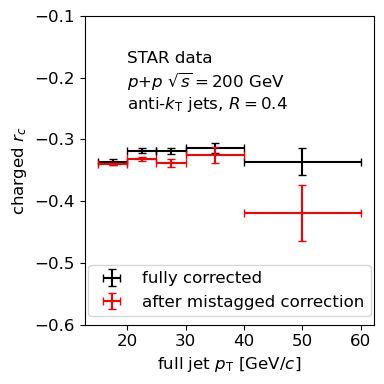

In [24]:
fig, ax = plt.subplots(figsize=(4, 4))
ax.errorbar(PT_CENTERS, rc_match_corrected, xerr=PT_XERR, yerr=rc_err_tot,
            capsize=3, color='k', ls='none', label='fully corrected')
ax.errorbar(PT_CENTERS, rc1_array, xerr=PT_XERR, yerr=rc1_err_array,
            capsize=3, color='r', ls='none', label='after mistagged correction')
ax.set_xlabel('full jet $p_{\\mathrm{T}}$ [GeV$/c$]')
ax.set_ylabel('charged $r_c$')
ax.set_ylim(-0.6, -0.1)
ax.legend(loc='lower center')
ax.text(20, -0.25, 'STAR data\n$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')
plt.tight_layout()

# Check $r_c$ correction is not needed

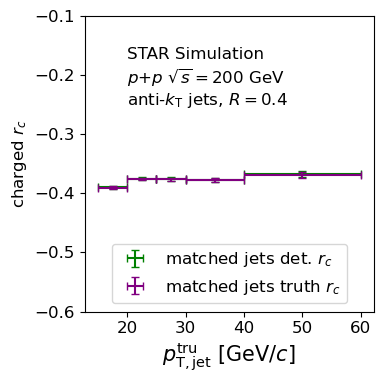

In [31]:
rc_match_bs, err_match_bs = get_rc_and_err_arr(df_match_pt, 'bs')
rc_match_b,  err_match_b  = get_rc_and_err_arr(df_match_pt, 'b')

fig, ax = plt.subplots(figsize=(4, 4))
ax.errorbar(PT_CENTERS, rc_match_bs, xerr=PT_XERR, yerr=err_match_bs,
            capsize=3, color='g',      ls='none', label='matched jets det. $r_c$')
ax.errorbar(PT_CENTERS, rc_match_b,  xerr=PT_XERR, yerr=err_match_b,
            capsize=3, color='purple', ls='none', label='matched jets truth $r_c$')
ax.set_xlabel(r'$p_{\mathrm{T,jet}}^{\mathrm{tru}}$ [GeV$/c$]', fontsize=15)
ax.set_ylabel('charged $r_c$')
ax.set_ylim(-0.6, -0.1)
ax.legend(loc='lower center')
ax.text(20, -0.25, 'STAR Simulation\n$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')
plt.tight_layout()